# Chile: CMF B-1, IFRS 9 and the Bank of Spain Annex 9 on one portfolio (Banco Andino)

**Question:** How much provision does a synthetic Chilean bank book under the CMF B-1 standard method, how much would IFRS 9 and the Bank of Spain Annex 9 give on the same loans, and what explains the gap between them?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 04 of this topic
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- say why Chilean banks do not book IFRS 9 impairment on loans, and where the CMF's B-1 provisions come from;
- read the B-1 standard method, the factor $PE = PI \times PDI$ by group, the maximum rule between the standard and an internal method, the 0.50% minimum and the additional provisions, and compute each with the engine on constructed accounts;
- read the Bank of Spain Annex 9 coverage tables and the mapping of its categories to the IFRS 9 stages;
- provision one synthetic bank under the three regimes, and read the gap between B-1 and IFRS 9 as a bridge of measurement choices;
- say what happens to the gap between the regimes when the economy is stressed in five different ways.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
SEGMENT = {
    "mortgage-ltv-le80": "mortgages up to 80% loan-to-value",
    "mortgage-ltv-gt80": "mortgages over 80% loan-to-value",
    "consumer-instalment": "consumer instalment loans",
    "consumer-cards": "consumer cards",
    "commercial-group": "commercial, group assessment",
    "commercial-individual": "commercial, individual assessment",
}
STEP = {
    "measurement-basis": "measurement basis", "lifetime-horizon": "lifetime horizon",
    "forward-looking": "scenario weighting", "discounting": "discounting",
    "b1-minimum-top-up": "B-1 minimum", "ifrs9-overlays": "overlays",
}
SCENARIO = {
    "base": "base", "recession": "recession", "house-price-fall": "house prices",
    "consumer-arrears-shock": "consumer arrears", "uf-inflation-spike": "UF inflation",
    "combined-severe": "combined severe",
}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is case C07, **Banco Andino**, a **synthetic** bank generated and calibrated to public aggregates of the CMF, Chile's financial market commission. It is not a real bank and not evidence about any bank; the committed notice says so, and the notebook prints it. Its book has six segments (mortgages by loan-to-value, consumer instalment loans, cards, and commercial loans by group or individual assessment) and about 171,000 accounts, in Chilean pesos (CLP). The same book is provisioned under three regimes and under six scenarios, one file each.

- **Files read:** `data/derived/C07/base.json`, `recession.json`, `house-price-fall.json`, `consumer-arrears-shock.json`, `uf-inflation-spike.json` and `combined-severe.json`, and `data/derived/C07/models-banco-andino.json` for the model slots. In each scenario file: `outputs.comparison` (the three provisions by segment), `outputs.gap_bridge`, `outputs.b1_detail`, `outputs.ifrs9_detail`, `outputs.bde_detail` and, from the second scenario on, `outputs.delta_vs_base`.
- **The regimes:** CMF B-1 is the statutory provision Chilean banks book on loans; the IFRS 9 column is a **comparison measure** and not what Chilean banks book (CNCB chapter A-2 N 5 leaves loans to B-1); the Bank of Spain Annex 9 is the Spanish GAAP alternative solution.
- **Assumptions of the case:** the scenario shocks, the overlays and the additional provisions are assumptions of the case, not Chilean paths or data.

The next cell loads the six scenarios and the model file and prints the committed notice, the model slots and the engine versions.

In [2]:
# Load the six scenarios of Banco Andino and print the notice, the model slots and the versions
from riskvalidation.provisions import local_cl as cl, local_es as es

LANG = "en"
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived" / "C07"
scenarios = {n: json.loads((DERIVED / f"{n}.json").read_text(encoding="utf-8")) for n in SCENARIO}
models = json.loads((DERIVED / "models-banco-andino.json").read_text(encoding="utf-8"))
base_art = scenarios["base"]
out = base_art["outputs"]
print(out["notice"][LANG])
baked = sorted({s["provenance"]["riskvalidation_version"] for s in scenarios.values()})
print("engine that baked the six scenarios:", *baked)
print("engine installed now:", md.version("riskvalidation"))
print("model slots:", len(models["model"]))
print("accounts:", sum(seg["accounts"] for seg in out["portfolio"]["segments"]))
gross_total = sum(seg["gross_exposure"] for seg in out["portfolio"]["segments"])
print("gross exposure, CLP billions:", round(gross_total / 1e9, 1))

Synthetic data: Banco Andino is a generated bank calibrated to public CMF system aggregates, not a real bank and not evidence about any bank. CMF B-1 is the statutory provision Chilean banks book on loans; the IFRS 9 column is a comparison measure, not the provision Chilean banks book on loans (CNCB A-2 N° 5 leaves loans to B-1); BdE Annex 9 is the Spanish GAAP alternative solution. Amounts in CLP.
engine that baked the six scenarios: 1.0.1
engine installed now: 1.0.1
model slots: 4
accounts: 171500
gross exposure, CLP billions: 6000.0


## Method

**Why three regimes.** Chilean banks adopted IFRS 9 in the CMF's accounting compendium (CNCB) in 2022 **except** the impairment chapter for loans: the provisions on loans and contingent credits stay under chapters B-1 to B-3 (CNCB A-2 N 5). The B-1 provision is a supervisory formula, not an expected credit loss. Spanish banks, under Circular 4/2017 of the Bank of Spain, do apply the IFRS 9 model, with supervisory "alternative solutions" for the collective estimate. Contraste provisions one synthetic bank under the three, to show where they agree and where they do not.

**CMF B-1, the standard methods** (CNCB B-1 N 3). For a group portfolio the provision factor is the product of the probability of default and the loss given default of the cell of a table, by exposure group and days past due:

$$PE = PI \times PDI, \qquad \mathrm{Prov}_{\mathrm{group}} = EG\,(1 - s)\,PE_{\mathrm{group}} + EG\,s\,PE_{\mathrm{guarantor}}, \qquad \mathrm{Prov} = \max\bigl(\mathrm{Prov}^{\mathrm{standard}}, \mathrm{Prov}^{\mathrm{internal}}\bigr)$$

with $EG$ the group exposure and $s$ the guaranteed share (B-1 N 4.1); the maximum rule applies unless the internal method has the CMF's "no objection" (B-1 N 3). An individually assessed debtor has a category A1 to A6 (normal) or B1 to B4 (substandard) with its own $PE$ (N 2.1). The minimum provision of 0.50% applies to the individually assessed normal portfolio only, and the additional (counter-cyclical) provisions are a separate line, inside the board's policy limits and never part of the comparable total (N 9).

**The Bank of Spain Annex 9** (Circular 4/2017, as amended by Circular 6/2021, tables of points 140, 144 and 172 from 30 June 2022). The coverage is a coefficient of the amount not covered by effective guarantees, by segment and risk category:

$$\mathrm{Coverage} = c_{s,k}\,\max\Bigl(0,\ \mathrm{EAD} - \sum_g \mathrm{AdjustedValue}_g\Bigr)$$

with normal and special-watch risk by point 144, doubtful risk by arrears by point 140, and the mapping of categories to stages (normal to Stage 1, special watch to Stage 2, doubtful to Stage 3).

**IFRS 9 as a comparison measure** is the probability-weighted ECL of notebooks 01 to 03 with overlays as separate lines (notebook 04). The engine's functions compute and state no compliance claim; the Annex 9 point numbers are those of Circular 6/2021 and whether they moved after Circular 1/2025 is not verified here.

### Step 1: the B-1 mortgage table, cell by cell

The engine holds the B-1 tables transcribed cell by cell, with the source paragraph in the code. `b1_mortgage_pe` returns, for a loan-to-value ratio (PVG) and an arrears bucket, the probability of default $PI$, the loss given default $PDI$ and their product $PE$. We call it on constructed accounts, four PVG levels in a table and a fine grid of PVG for each of the five arrears buckets in the figure, to see the shape of the table the bank's whole mortgage book is provisioned with.

PVG 0.35 | PI 0.010916 | PDI 0.000225 | PE 0.000002 | PI x PDI 0.000002
PVG 0.60 | PI 0.019158 | PDI 0.021955 | PE 0.000421 | PI x PDI 0.000421
PVG 0.85 | PI 0.025150 | PDI 0.215527 | PE 0.005421 | PI x PDI 0.005421
PVG 0.95 | PI 0.027400 | PDI 0.272000 | PE 0.007453 | PI x PDI 0.007453


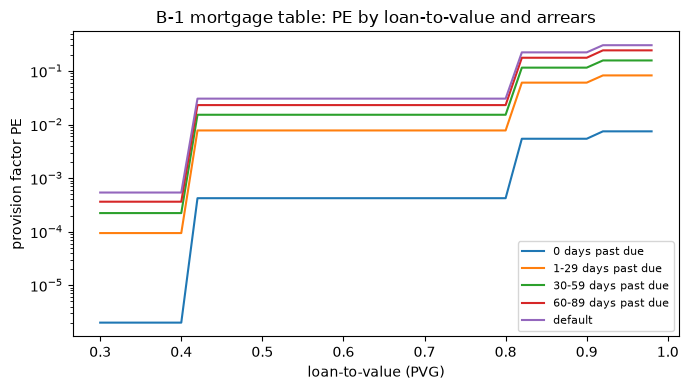

In [3]:
# Read the B-1 mortgage table at four loan-to-value levels and draw the PE by arrears bucket
for pvg in (0.35, 0.60, 0.85, 0.95):
    pi, pdi, pe_cell = cl.b1_mortgage_pe(pvg, "0")
    print(f"PVG {pvg:.2f} | PI {pi:.6f} | PDI {pdi:.6f} | PE {pe_cell:.6f} | PI x PDI {pi * pdi:.6f}")
grid = np.linspace(0.30, 0.98, 35)
buckets = ("0", "1-29", "30-59", "60-89", "default")
curves = {bucket: [cl.b1_mortgage_pe(float(v), bucket)[2] for v in grid] for bucket in buckets}

fig, ax = plt.subplots(figsize=(7, 4))
for bucket in buckets:
    label = "default" if bucket == "default" else f"{bucket} days past due"
    ax.plot(grid, curves[bucket], label=label)
ax.set_yscale("log")
ax.set_xlabel("loan-to-value (PVG)")
ax.set_ylabel("provision factor PE")
ax.set_title("B-1 mortgage table: PE by loan-to-value and arrears")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

For a mortgage with a loan-to-value between 40% and 80% and no arrears the table gives $PI = 0.019158$ and $PDI = 0.021955$, so $PE = 0.000421$, and the printed product of the two factors is the same number. The curves rise steeply with the loan-to-value and with arrears: the factor at PVG 0.35 is 0.000002 and in default at the top of the range it reaches 0.302436, five orders of magnitude apart. The steps of each curve are the cell boundaries of the table, so the provision of a mortgage is decided by which cell it falls in, not by a smooth model.

### Step 2: the commercial, consumer and individual cells

Commercial group loans have a table by days past due and by the ratio of the loan to the value of its guarantee (PTVG), consumer loans a table by arrears and by whether the debtor has a mortgage in the system, and an individually assessed debtor has a category A1 to A6 or B1 to B4 with its own factor. The cell calls the engine's lookups on constructed accounts, one case each, and then asks for an arrears bucket the table does not have, to see the engine refuse it and not guess.

In [4]:
# Read the commercial, consumer and individual B-1 cells for constructed accounts
print("commercial, current, guarantee at PTVG 0.8 and no guarantee (PI, PDI, PE):")
print([round(v, 6) for v in cl.b1_commercial_pe("0", 0.8)], [round(v, 6) for v in cl.b1_commercial_pe("0", None)])
print("consumer instalment loan, 5 days late, mortgage in the system, no arrears (PI, PDI, PE):")
print([round(v, 6) for v in cl.b1_consumer_pe(5, True, False, "instalment")])
print("individual categories (PI, PDI, PE):")
for category in ("A1", "A4", "B4"):
    print(category, [round(v, 6) for v in cl.b1_individual_category(category)])
print("group provision, exposure 1000, group PE 0.05, guaranteed share 0.20, guarantor PE 0.01:")
print(round(cl.b1_group_provision(1000.0, 0.05, 0.20, 0.01), 4))
try:
    cl.b1_mortgage_pe(0.6, "45")
except ValueError as error:
    print("a bucket the table does not have is refused with", type(error).__name__)

commercial, current, guarantee at PTVG 0.8 and no guarantee (PI, PDI, PE):
[0.0186, 0.322, 0.005989] [0.0491, 0.569, 0.027938]
consumer instalment loan, 5 days late, mortgage in the system, no arrears (PI, PDI, PE):
[0.033, 0.477, 0.015741]
individual categories (PI, PDI, PE):
A1 [0.0004, 0.9, 0.00036]
A4 [0.02, 0.875, 0.0175]
B4 [0.45, 0.975, 0.43875]
group provision, exposure 1000, group PE 0.05, guaranteed share 0.20, guarantor PE 0.01:
42.0
a bucket the table does not have is refused with ValueError


A current commercial loan with a guarantee at a PTVG of 0.8 carries a factor of 0.005989 and without a guarantee 0.027938, so the guarantee divides the provision by almost five. The consumer instalment loan of the example carries 0.015741. The individual categories climb from 0.00036 for A1 to 0.0175 for A4 and 0.43875 for B4, a factor of more than a thousand between the best normal debtor and a substandard one. Every one of these is a lookup in a table, and the refusal of the bucket `45` shows that the tables are closed: an input that is not a cell is an error.

### Step 3: the group provision, the maximum rule, the minimum and the additional provisions

`b1_group_provision` computes $EG(1-s)PE + EG\,s\,PE_{\mathrm{guarantor}}$; `b1_group_max_rule` returns the larger of the standard and the internal provision unless the internal method has the CMF's no objection, and the standard one when there is no internal method; `b1_minimum_normal_check` tests the 0.50% minimum of the normal individual portfolio; `b1_additional_provisions` accepts an amount only inside the board's policy range. The cell runs them on one constructed example and on Banco Andino's committed detail, and draws the maximum rule for each group segment.

In [5]:
# Compute the group rules, the minimum and the additional provisions on the committed detail
detail = out["b1_detail"]
rows = detail["group_max_rule"]
applied = [cl.b1_group_max_rule(r["standard"], r["internal"])[0] for r in rows]
print("applied, CLP millions:", [round(a / 1e6, 1) for a in applied])
minimum = detail["minimum_check"]
exposure, before = minimum["normal_portfolio_exposure"], minimum["normal_portfolio_provision_before_minimum"]
check = cl.b1_minimum_normal_check(exposure, before)
tight = cl.b1_minimum_normal_check(exposure, 5e9)
print("minimum of the normal portfolio, CLP millions:", round(check.minimum_amount / 1e6, 1))
print("binding:", "yes" if check.binding else "no", "| top-up, CLP millions:", round(check.top_up / 1e6, 1))
print("top-up with a provision of 5 billion, CLP millions:", round(tight.top_up / 1e6, 1))
extra = detail["additional_provisions"]
accepted = cl.b1_additional_provisions(extra["amount"], extra["policy_min"], extra["policy_max"])
print("additional provisions inside the policy, CLP millions:", accepted / 1e6)
try:
    cl.b1_additional_provisions(20e9, extra["policy_min"], extra["policy_max"])
except ValueError as error:
    print("outside the policy it is refused with", type(error).__name__)

applied, CLP millions: [1626.7, 11229.1, 29229.0, 26899.5, 24191.8]
minimum of the normal portfolio, CLP millions: 8457.4
binding: no | top-up, CLP millions: 0.0
top-up with a provision of 5 billion, CLP millions: 3457.4
additional provisions inside the policy, CLP millions: 3000.0
outside the policy it is refused with ValueError


The group provision of the example is 42.0, the formula with its three inputs; the applied provisions, the minimum with its top-up and the additional provisions are in the output above. The next cell draws the maximum rule for the five group segments of the committed detail.

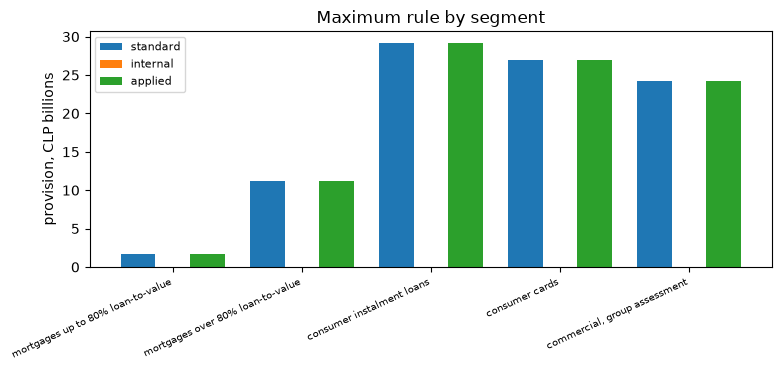

In [6]:
# Draw the maximum rule: the standard, the internal and the applied provision of each group segment
x = np.arange(len(rows))
fig, ax = plt.subplots(figsize=(8, 3.8))
internal = [float("nan") if r["internal"] is None else r["internal"] / 1e9 for r in rows]
series = (([r["standard"] / 1e9 for r in rows], "tab:blue", "standard"), (internal, "tab:orange", "internal"),
          ([a / 1e9 for a in applied], "tab:green", "applied"))
for k, (values, color, label) in enumerate(series):
    ax.bar(x + (k - 1) * 0.27, values, width=0.27, color=color, label=label)
ax.set_xticks(x)
ax.set_xticklabels([SEGMENT[r["segment_id"]] for r in rows], rotation=25, ha="right", fontsize=7)
ax.set_ylabel("provision, CLP billions")
ax.set_title("Maximum rule by segment")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Banco Andino has no internal method, so the orange bars are absent and the standard provision is the applied one in all the group segments: the maximum rule has nothing to compare. The minimum of the normal individual portfolio is 8,457.4 million CLP and does not bind, but with a provision of 5,000 million it would bind with a top-up of 3,457.4 million, which shows what the rule is for. The additional provisions of 3,000 million are inside the board's range and an amount of 20,000 million is refused, because the engine accepts the line only inside the policy. The example provision of 42.0 is the formula with its three inputs.

### Step 4: the Annex 9 tables

`annex9_normal_coverage` reads point 144 and `annex9_doubtful_coverage` point 140, by segment code (A.* for businesses, B.* for households) and by days past due. `annex9_coverage` applies the coefficient to the amount not covered by guarantees adjusted by their haircuts. The cell reads the coefficients for housing, consumer and construction, computes the coverage of one constructed account, and offers a doubtful account with no days past due, which the engine must refuse. The figure draws the doubtful coverage of housing against the days past due, a step function of the table of point 140.

point 144, housing, normal and special watch: 0.007 0.18
point 144, consumer and construction, normal: 0.018 0.019
coverage: EAD 1000, adjusted guarantees 300, housing normal: 4.9
a doubtful account without days past due is refused with ValueError


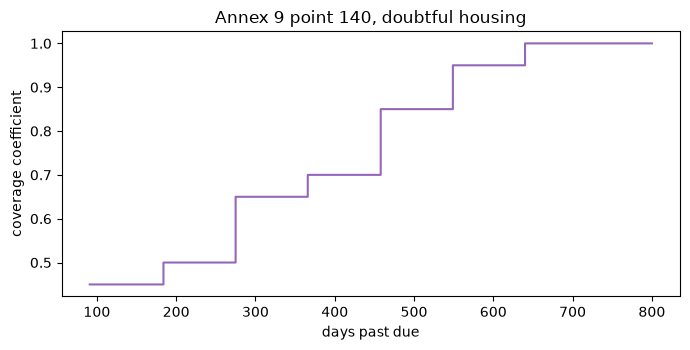

In [7]:
# Read the Annex 9 coefficients and draw the doubtful coverage by days past due
housing = (es.annex9_normal_coverage("B.1.1", "normal"), es.annex9_normal_coverage("B.1.1", "normal-special-watch"))
print("point 144, housing, normal and special watch:", *housing)
print("point 144, consumer and construction, normal:", es.annex9_normal_coverage("B.2", "normal"),
      es.annex9_normal_coverage("A.1.1", "normal"))
coverage = es.annex9_coverage("B.1.1", "normal", 1000.0, [300.0])
print("coverage: EAD 1000, adjusted guarantees 300, housing normal:", coverage)
try:
    es.annex9_coverage("B.1.1", "doubtful", 1000.0, [])
except ValueError as error:
    print("a doubtful account without days past due is refused with", type(error).__name__)

days = np.arange(91, 801)
coefficients = [es.annex9_doubtful_coverage("B.1.1", int(d)) for d in days]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.step(days, coefficients, where="post", color="tab:purple")
ax.set_xlabel("days past due")
ax.set_ylabel("coverage coefficient")
ax.set_title("Annex 9 point 140, doubtful housing")
fig.tight_layout()
plt.show()

The Annex 9 coefficients are a different object from the B-1 factors. For normal housing risk the coefficient is 0.007 and for special watch 0.18, 26 times larger, so moving an account to special watch is the largest single step; consumer credit is 0.018 and construction 0.019. The doubtful coefficient of housing is a staircase: 0.45 up to 183 days, 0.50 from 184, 0.65 at 365 and 1.0 at 700. An account of 1,000 with guarantees of 300 in normal housing has a coverage of 4.9, the coefficient applied to the 700 not covered. The refusal of a doubtful account with no arrears shows that the engine does not invent a coefficient.

### Step 5: the committed Annex 9 categories and their stage

Banco Andino's Annex 9 view is committed by risk category, with the exposure and the provision of each. The engine's `annex9_category_to_stage` maps a category to an IFRS 9 stage: normal to Stage 1, special watch to Stage 2 and doubtful to Stage 3. The cell asks the engine for the stage of each committed category and prints it beside the coverage rate, the provision over the exposure, so the Annex 9 book can be read in the IFRS 9 language of the other notebooks.

In [8]:
# Map the committed Annex 9 categories to stages with the engine and read their coverage rates
categories = out["bde_detail"]["categories"]
for k, row in enumerate(categories, start=1):
    stage = es.annex9_category_to_stage(row["category"])
    rate = row["provision"] / row["exposure"]
    print("category", k, "| mapped stage:", str(stage)[-1], "| coverage rate:", round(rate, 6))

category 1 | mapped stage: 1 | coverage rate: 0.003723
category 2 | mapped stage: 2 | coverage rate: 0.057243
category 3 | mapped stage: 3 | coverage rate: 0.26521


The coverage rate grows with the stage the engine assigns: 0.3723% for the normal category in Stage 1, 5.7243% for special watch in Stage 2 and 26.5210% for the doubtful one in Stage 3. This is the same ladder as the IFRS 9 coverage by stage of notebook 02, built here from a supervisory table and not from a lifetime model, and it makes the comparison of the next step fair: the three regimes differ in how they reach the coverage of each stage, not in whether stages exist.

### Step 6: one portfolio, three provisions

Now the three regimes side by side on the base scenario. `outputs.comparison` gives, for each segment, the B-1 provision, the IFRS 9 ECL and the Annex 9 coverage, plus the unallocated lines (the IFRS 9 overlays). The cell sums the segments and the unallocated lines of each regime, prints the three totals and their ratios to B-1, and prints the coverage by segment, the provision over the gross exposure. The figure draws that coverage for the six segments.

CMF B-1    provision, CLP billions:   152.001
IFRS 9     provision, CLP billions:    97.592
Annex 9    provision, CLP billions:    79.618
IFRS 9 over B-1: 0.6421
Annex 9 over B-1: 0.5238
coverage by segment: B-1, IFRS 9, Annex 9
  mortgage-ltv-le80        0.0011   0.0064   0.0000
  mortgage-ltv-gt80        0.0171   0.0107   0.0038
  consumer-instalment      0.0801   0.0259   0.0441
  consumer-cards           0.0844   0.0330   0.0332
  commercial-group         0.0187   0.0088   0.0093
  commercial-individual    0.0302   0.0255   0.0197


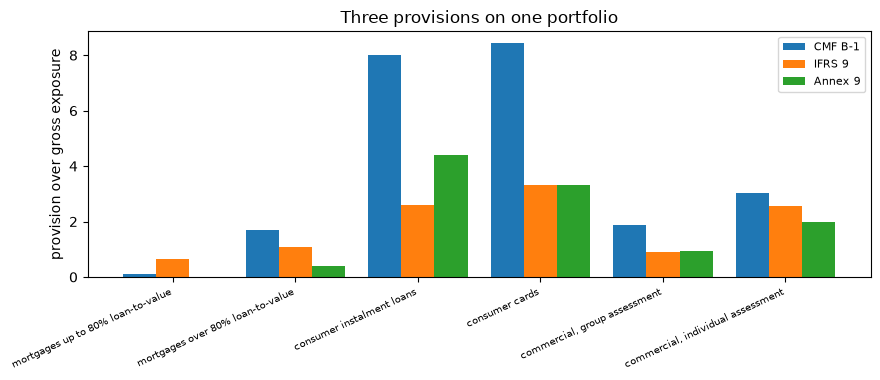

In [9]:
# Sum the segments of each regime, compare the three totals and draw the coverage by segment
comparison = out["comparison"]
gross = {s["segment_id"]: s["gross_exposure"] for s in out["portfolio"]["segments"]}
KEYS = ("cmf_b1_provision", "ifrs9_provision", "bde_annex9_provision")
NAMES = ("CMF B-1", "IFRS 9", "Annex 9")
totals = {k: sum(r[k] for r in comparison["rows"]) + comparison["unallocated"][k] for k in KEYS}
for key, name in zip(KEYS, NAMES):
    print(f"{name:10s} provision, CLP billions: {totals[key] / 1e9:9.3f}")
print("IFRS 9 over B-1:", round(totals[KEYS[1]] / totals[KEYS[0]], 4))
print("Annex 9 over B-1:", round(totals[KEYS[2]] / totals[KEYS[0]], 4))
rates = {r["segment_id"]: [r[k] / gross[r["segment_id"]] for k in KEYS] for r in comparison["rows"]}
print("coverage by segment: B-1, IFRS 9, Annex 9")
for segment, rate in rates.items():
    print(f"  {segment:22s}", *[f"{v:8.4f}" for v in rate])

x = np.arange(len(rates))
fig, ax = plt.subplots(figsize=(9, 3.9))
for k, (name, color) in enumerate(zip(NAMES, ("tab:blue", "tab:orange", "tab:green"))):
    ax.bar(x + (k - 1) * 0.27, [100 * r[k] for r in rates.values()], width=0.27, color=color, label=name)
ax.set_xticks(x)
ax.set_xticklabels([SEGMENT[s] for s in rates], rotation=25, ha="right", fontsize=7)
ax.set_ylabel("provision over gross exposure")
ax.set_title("Three provisions on one portfolio")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The same book gets three totals: 152.001 billion CLP under B-1, 97.592 under IFRS 9, including 0.324 of overlays as unallocated lines, and 79.618 under Annex 9. IFRS 9 is 64.21% of B-1 and Annex 9 is 52.38%. The order is not the same in every segment: the mortgages up to 80% loan-to-value carry 0.11% under B-1, 0.64% under IFRS 9 and nothing under Annex 9, while the consumer instalment loans carry 8.01%, 2.59% and 4.41%. A single ratio between regimes hides that the regimes disagree in opposite directions on different products, and the figure percentages are the provision over the gross exposure.

### Step 7: the bridge from B-1 to IFRS 9

The gap between two regimes is a sum of choices. `outputs.gap_bridge` lists the steps from the B-1 total to the IFRS 9 total: the measurement basis (the bank's own PD, loss given default and recoveries against the B-1 matrices, over twelve months, central and undiscounted), the lifetime horizon for Stage 2, the probability weighting of the scenarios, the discounting at the original EIR, the B-1 minimum top-up that IFRS 9 does not have, and the overlays. The cell walks the steps in order, printing the running level, and the figure draws them as a waterfall.

B-1                      152.001
measurement basis        -92.548 ->    59.452
lifetime horizon         +17.134 ->    76.587
scenario weighting       +11.625 ->    88.212
discounting               +9.056 ->    97.268
B-1 minimum               +0.000 ->    97.268
overlays                  +0.324 ->    97.592


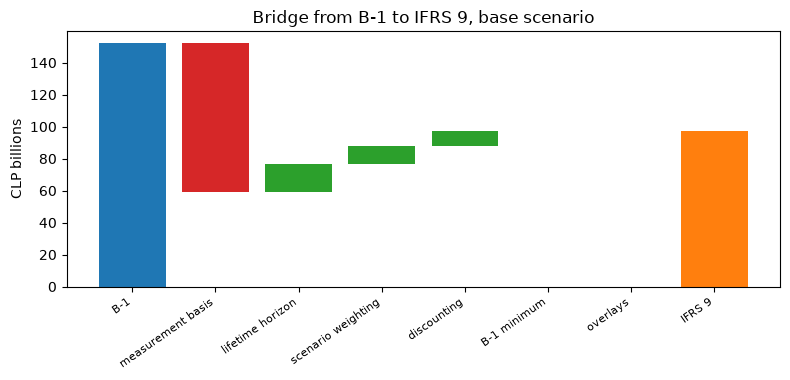

In [10]:
# Walk the bridge from B-1 to IFRS 9 and draw it
steps = out["gap_bridge"]["steps"]
level = totals[KEYS[0]] / 1e9
print(f"{'B-1':22s} {level:9.3f}")
fig, ax = plt.subplots(figsize=(8, 3.9))
ax.bar(0, level, color="tab:blue")
labels = ["B-1"]
for i, step in enumerate(steps, start=1):
    amount = step["amount"] / 1e9
    bottom, color = (level, "tab:green") if amount >= 0 else (level + amount, "tab:red")
    ax.bar(i, abs(amount), bottom=bottom, color=color)
    level += amount
    labels.append(STEP[step["id"]])
    print(f"{STEP[step['id']]:22s} {amount:+9.3f} -> {level:9.3f}")
ax.bar(len(steps) + 1, level, color="tab:orange")
labels.append("IFRS 9")
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=35, ha="right", fontsize=8)
ax.set_ylabel("CLP billions")
ax.set_title("Bridge from B-1 to IFRS 9, base scenario")
fig.tight_layout()
plt.show()

From 152.001 billion CLP under B-1 the measurement basis takes off 92.548, the lifetime loss on Stage 2 adds 17.134, the probability weighting 11.625, the discounting at the EIR 9.056, the B-1 minimum top-up nothing and the overlays 0.324, which lands on 97.592, the IFRS 9 total. The gap of about 54 billion is mostly the first step: the bank's own PD, loss given default and recoveries against the B-1 matrices are far lower than the matrices, and the later steps, which are the lifetime and forward-looking features of IFRS 9, add back only about 38 billion of the 92.548 taken off.

### Step 8: the same bank under five stresses

The five stress files change the economy (a recession, a house price fall, a consumer arrears shock, a spike of UF inflation and a combined severe case) and provision the same bank again under the three regimes. The cell reads the three provisions of each scenario, prints them with the ratio of IFRS 9 to B-1, and prints the committed change of the combined severe case against the base. The figure draws the provision of each regime in each of the six scenarios.

base                 B-1   152.0 | IFRS 9    97.6 | Annex 9    79.6
                     IFRS 9 over B-1:  0.642
recession            B-1   197.5 | IFRS 9   169.8 | Annex 9   116.3
                     IFRS 9 over B-1:  0.860
house prices         B-1   168.9 | IFRS 9   128.8 | Annex 9    94.6
                     IFRS 9 over B-1:  0.763
consumer arrears     B-1   178.6 | IFRS 9   126.3 | Annex 9    97.3
                     IFRS 9 over B-1:  0.707
UF inflation         B-1   166.9 | IFRS 9   117.4 | Annex 9    85.6
                     IFRS 9 over B-1:  0.703
combined severe      B-1   275.8 | IFRS 9   327.8 | Annex 9   191.6
                     IFRS 9 over B-1:  1.189
combined severe against the base, CLP billions (B-1, IFRS 9, Annex 9):
123.8 230.2 112.0


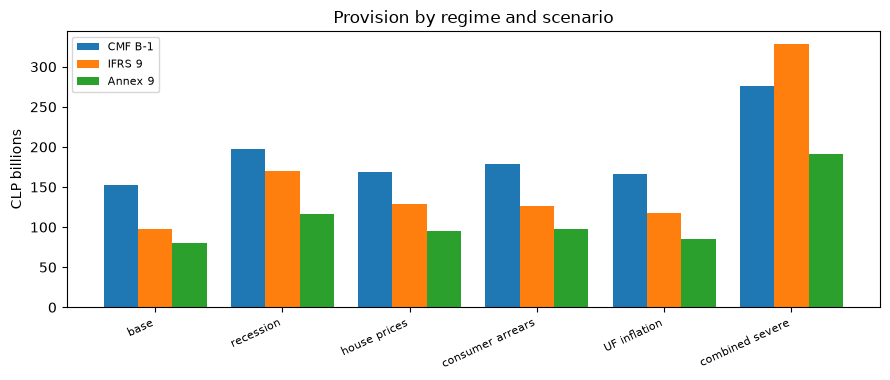

In [11]:
# Read the three provisions in the six scenarios and draw them
regime_rows = {n: a["outputs"]["regimes"] for n, a in scenarios.items()}
by_regime = {n: {r["regime"]: r["total_provision"] / 1e9 for r in rs} for n, rs in regime_rows.items()}
for name, regimes in by_regime.items():
    b1, ifrs9_total, annex = regimes["cmf-b1"], regimes["ifrs9"], regimes["bde-annex9"]
    print(f"{SCENARIO[name]:20s} B-1 {b1:7.1f} | IFRS 9 {ifrs9_total:7.1f} | Annex 9 {annex:7.1f}")
    print(f"{'':20s} IFRS 9 over B-1: {ifrs9_total / b1:6.3f}")
delta = scenarios["combined-severe"]["outputs"]["delta_vs_base"]
print("combined severe against the base, CLP billions (B-1, IFRS 9, Annex 9):")
changes = (delta["cmf_b1_delta"], delta["ifrs9_delta"], delta["bde_annex9_delta"])
print(*[round(c / 1e9, 1) for c in changes])

x = np.arange(len(by_regime))
fig, ax = plt.subplots(figsize=(9, 3.9))
for k, (regime, color, label) in enumerate((("cmf-b1", "tab:blue", "CMF B-1"), ("ifrs9", "tab:orange", "IFRS 9"),
                                            ("bde-annex9", "tab:green", "Annex 9"))):
    ax.bar(x + (k - 1) * 0.27, [r[regime] for r in by_regime.values()], width=0.27, color=color, label=label)
ax.set_xticks(x)
ax.set_xticklabels([SCENARIO[n] for n in by_regime], rotation=25, ha="right", fontsize=8)
ax.set_ylabel("CLP billions")
ax.set_title("Provision by regime and scenario")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The ranking of the regimes does not survive every stress. The ratio of IFRS 9 to B-1 is 0.642 in the base and rises to 0.860 in the recession, 0.763 with the house price fall, 0.707 with the consumer arrears shock and 0.703 with the UF inflation spike. In the combined severe case it is 1.189: IFRS 9 reaches 327.8 billion against 275.8 for B-1. From the base to that case B-1 rises by 123.8 billion, IFRS 9 by 230.2 and Annex 9 by 112.0. A table-based provision moves with the arrears buckets and an expected loss moves with the forecast, so the forward-looking regime is the one that reacts most when the economy deteriorates.

## Results

**Answer:** On the base scenario Banco Andino provisions 152.001 billion CLP under B-1, 97.592 under IFRS 9 and 79.618 under Annex 9, so IFRS 9 is 0.6421 of B-1, and the gap is mostly one choice: the measurement basis alone takes off 92.548 billion, which the lifetime horizon (17.134), the scenario weighting (11.625), the discounting (9.056) and the overlays (0.324) only partly give back; the order does not survive a severe stress, since in the combined severe scenario IFRS 9 reaches 327.8 billion against 275.8 for B-1.

- **The B-1 tables read as transcribed.** For a mortgage with a loan-to-value between 40% and 80% and no arrears, $PI = 0.019158$ and $PDI = 0.021955$, so $PE = 0.000421$; at PVG 0.35 it is 0.000002. A current commercial loan with a guarantee at a PTVG of 0.8 has $PE = 0.005989$ and without a guarantee 0.027938; the individual categories A1, A4 and B4 have 0.00036, 0.0175 and 0.43875.
- **The group rules compute as the compendium says.** With an exposure of 1,000, a $PE$ of 0.05 and 20% guaranteed at 0.01 the provision is 42.0. Banco Andino has no internal method, so the standard provision is the applied one in all the group segments.
- **The minimum and the additional provisions are separate.** The 0.50% minimum of the individually assessed normal portfolio is 8,457.4 million CLP and does not bind; with a provision of 5,000 million it would bind with a top-up of 3,457.4. The additional provisions of 3,000 million are inside the board's range and an amount of 20,000 is refused.
- **Annex 9 reads as a coefficient on the uncovered amount.** Housing normal risk is 0.007 and special watch 0.18; consumer credit 0.018; construction 0.019. For doubtful housing risk the coefficient is 0.45 up to 183 days and 1.0 at 700. The categories map to Stages 1, 2 and 3 with coverage rates of 0.3723%, 5.7243% and 26.5210%.
- **One portfolio, three totals.** IFRS 9 is 64.21% of B-1 and Annex 9 is 52.38%. By segment the order changes: the mortgages up to 80% loan-to-value carry 0.11% under B-1, 0.64% under IFRS 9 and nothing under Annex 9, while the consumer instalment loans carry 8.01%, 2.59% and 4.41%.
- **The bridge is a list of choices.** From 152.001 billion under B-1 the measurement basis takes off 92.548, the lifetime loss on Stage 2 adds 17.134, the probability weighting 11.625, the discounting 9.056 and the overlays 0.324, which gives 97.592.
- **The ranking of the regimes does not survive every stress.** IFRS 9 over B-1 is 0.642 in the base and 0.860, 0.763, 0.707 and 0.703 in the recession, the house price fall, the consumer arrears shock and the UF inflation spike. In the combined severe case it is 1.189. From the base to that case B-1 rises by 123.8 billion, IFRS 9 by 230.2 and Annex 9 by 112.0.

What this notebook does not show: Banco Andino is synthetic, its shocks, overlays and additional provisions are assumptions of the case, and the IFRS 9 column is a comparison measure that Chilean banks do not book on loans. The CMF's August 2026 reform proposal (recalibrated PI scale, internal methods) is not in force and is not implemented; the Annex 9 point numbers are those of Circular 6/2021. The notebook says nothing about whether any real bank would be provisioned this way.

## Summary

- Chilean banks book B-1 provisions on loans, not IFRS 9 impairment; B-1 is a table of $PE = PI \times PDI$ cells with a maximum rule, a minimum and a separate line of additional provisions, and the engine holds each table transcribed cell by cell.
- The Bank of Spain Annex 9 is a coefficient on the uncovered amount, by segment and category, with a mapping to the IFRS 9 stages.
- On one synthetic bank the three regimes give three totals; the gap between B-1 and IFRS 9 is a bridge of named choices, dominated by the measurement basis.
- The ranking of the regimes depends on the economy: IFRS 9 is far below B-1 in the base and above it in the combined severe case.
- Banco Andino is synthetic and its shocks are assumptions; the comparison teaches the mechanics, it does not value any real bank.

**What to try next.** Change the `pvg` and the arrears bucket of the mortgage lookup to read other cells; give `b1_group_max_rule` an internal amount above the standard one for a group segment and recompute the B-1 total. Then continue with notebook 07, which opens the lifetime PD models that feed the IFRS 9 column.

## References

- CMF Chile, Compendio de Normas Contables para Bancos (CNCB), Chapters A-2 (N 5) and B-1 (N 2, N 3, N 4 and N 9), Circular 2.346. https://www.cmfchile.cl/portal/normativa/624/articles-29177_doc_pdf.pdf
- Banco de España, Circular 4/2017, norma 29 and Anejo 9 (BOE-A-2017-14334). https://www.boe.es/buscar/act.php?id=BOE-A-2017-14334
- Banco de España, Circular 6/2021 of 22 December (BOE-A-2021-21666): the tables of points 140, 144 and 172, applicable from 30 June 2022. https://www.boe.es/buscar/doc.php?id=BOE-A-2021-21666
- IASB, IFRS 9 Financial Instruments (July 2014), as endorsed by Commission Regulation (EU) 2016/2067, paragraphs 5.5 and B5.5, and the IFRS 7 amendments 35A to 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- EBA (2023), IFRS 9 implementation by EU institutions, 2023 monitoring report, EBA/Rep/2023/36, paragraphs 29 to 33 and 94 to 118. https://www.eba.europa.eu/sites/default/files/2023-11/25b12d35-9c28-4335-a589-166c77198920/Final%20Report%20on%20IFRS9%20implementation%20by%20EU%20institutions.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), paragraphs 36, 50 and 51 and annex paragraph A26. https://www.bis.org/bcbs/publ/d350.htm